# Digitale Immobilienfinanzierung – Python-Prototypen

Dieses Notebook unterstützt das entwickelte End-to-End-Konzept für eine digitale private Immobilienfinanzierung.

Es enthält drei Anwendungen:

1. einen Annuitätenrechner zur Veranschaulichung einer Finanzierungsstruktur,
2. einen regelbasierten Routing-Prototyp zur Zuordnung von Finanzierungsfällen,
3. ein Prozesskostenmodell zur Abschätzung der wirtschaftlichen Wirkung des Fast-Track.

Die verwendeten Finanzierungsparameter sind illustrative eigene Annahmen und keine Marktprognose.
Der Routing-Prototyp dient ausschließlich der Prozessveranschaulichung und stellt kein produktives Kreditentscheidungsmodell dar.
Das Prozesskostenmodell ist eine Modellrechnung mit eigenen Annahmen und keine Kostenaussage für eine konkrete Bank.

## 1. Annuitätenrechner

Für ein illustratives Finanzierungsbeispiel werden folgende Annahmen verwendet:

- Kaufpreis: 500.000 €
- Eigenkapital: 100.000 €
- Darlehensbetrag: 400.000 €
- Sollzins: 3,50 % p. a.
- anfängliche Tilgung: 2,00 % p. a.
- Zinsbindung: 10 Jahre

Berechnet werden die monatliche Annuität sowie der Zins-, Tilgungs- und Restschuldverlauf über 120 Monate.

In [1]:
def eur(betrag, nachkomma=2):
    """Formatiert einen Betrag im deutschen Format, z. B. 1.833,33 €."""
    text = f"{betrag:,.{nachkomma}f}"
    return text.replace(",", "X").replace(".", ",").replace("X", ".") + " €"

kaufpreis = 500_000
eigenkapital = 100_000
darlehen = kaufpreis - eigenkapital

sollzins = 0.035
anfaengliche_tilgung = 0.02
zinsbindung_jahre = 10

monate = zinsbindung_jahre * 12
monatszins = sollzins / 12

monatsrate = darlehen * (sollzins + anfaengliche_tilgung) / 12

print(f"Darlehensbetrag: {eur(darlehen)}")
print(f"Monatliche Rate: {eur(monatsrate)}")

Darlehensbetrag: 400.000,00 €
Monatliche Rate: 1.833,33 €


In [2]:
restschuld = darlehen
tilgungsplan = []

for monat in range(1, monate + 1):
    zinsanteil = restschuld * monatszins
    tilgungsanteil = monatsrate - zinsanteil
    restschuld -= tilgungsanteil

    tilgungsplan.append({
        "Monat": monat,
        "Rate": monatsrate,
        "Zinsanteil": zinsanteil,
        "Tilgungsanteil": tilgungsanteil,
        "Restschuld": restschuld
    })

In [3]:
import pandas as pd

tilgungsplan_df = pd.DataFrame(tilgungsplan)

tilgungsplan_df.head()

,Monat,Rate,Zinsanteil,Tilgungsanteil,Restschuld
0,1,1833.333333,1166.666667,666.666667,399333.333333
1,2,1833.333333,1164.722222,668.611111,398664.722222
2,3,1833.333333,1162.772106,670.561227,397994.160995
3,4,1833.333333,1160.816303,672.517030,397321.643965
4,5,1833.333333,1158.854795,674.478538,396647.165427


In [4]:
restschuld_10_jahre = tilgungsplan_df.iloc[-1]["Restschuld"]
getilgter_betrag = darlehen - restschuld_10_jahre
gezahlte_zinsen = (
    tilgungsplan_df["Zinsanteil"].sum()
)

print(f"Monatliche Rate: {eur(monatsrate)}")
print(f"Getilgter Betrag nach 10 Jahren: {eur(getilgter_betrag)}")
print(f"Restschuld nach 10 Jahren: {eur(restschuld_10_jahre)}")
print(f"Gezahlte Zinsen in 10 Jahren: {eur(gezahlte_zinsen)}")

Monatliche Rate: 1.833,33 €
Getilgter Betrag nach 10 Jahren: 95.621,67 €
Restschuld nach 10 Jahren: 304.378,33 €
Gezahlte Zinsen in 10 Jahren: 124.378,33 €


### Restschuldverlauf über die Zinsbindung

Die Grafik zeigt, wie die Restschuld über die 120 Monate der Zinsbindung sinkt (Grundlage für die Darstellung in der Präsentation).

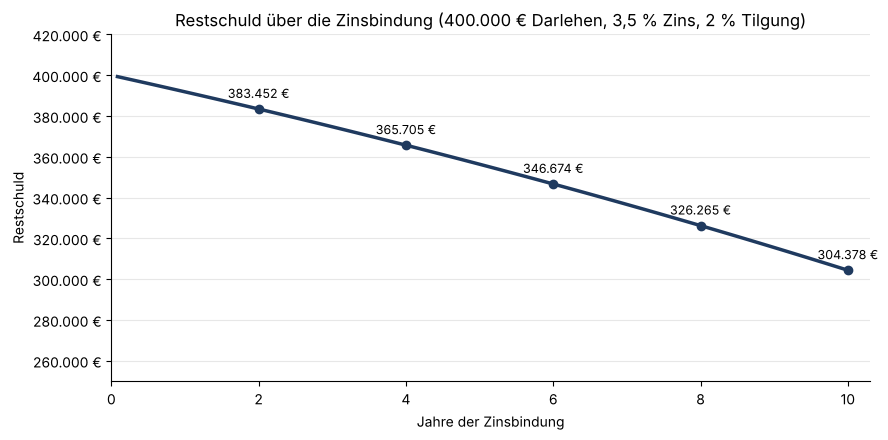

In [5]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(9, 4.5))
jahre = tilgungsplan_df["Monat"] / 12
ax.plot(jahre, tilgungsplan_df["Restschuld"], color="#1f3a5f", linewidth=2.5)

# Jahresendwerte markieren
jahresende = tilgungsplan_df[tilgungsplan_df["Monat"] % 24 == 0]
ax.scatter(jahresende["Monat"] / 12, jahresende["Restschuld"], color="#1f3a5f", zorder=3)
for _, zeile in jahresende.iterrows():
    ax.annotate(eur(zeile["Restschuld"], 0), (zeile["Monat"] / 12, zeile["Restschuld"]),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)

ax.set_title("Restschuld über die Zinsbindung (400.000 € Darlehen, 3,5 % Zins, 2 % Tilgung)")
ax.set_xlabel("Jahre der Zinsbindung")
ax.set_ylabel("Restschuld")
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: eur(y, 0)))
ax.set_xlim(0, 10.3)
ax.set_ylim(250_000, 420_000)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("restschuld.png", dpi=150)
plt.show()

## 2. Regelbasierter Routing-Prototyp

Der Prototyp zeigt, wie Finanzierungsfälle anhand weniger qualitativer Kriterien unterschiedlichen Bearbeitungswegen zugeordnet werden können.

Verwendete Kriterien:

- Vollständigkeit der Daten
- Konsistenz der Daten
- standardisierte Einkommensstruktur
- ausreichend eindeutige Immobilienbewertung
- wesentliches Risikomerkmal

Die Regeln dienen ausschließlich der Prozesssteuerung. Sie ersetzen keine Kreditwürdigkeitsprüfung und kein validiertes Kreditentscheidungsmodell.

Negative Kreditentscheidungen werden im entwickelten Zielmodell nicht ausschließlich automatisiert finalisiert.

In [6]:
def route_case(
    daten_vollstaendig,
    daten_konsistent,
    einkommen_standard,
    bewertung_sicher,
    wesentliches_risiko
):
    if wesentliches_risiko:
        return "Risikofall"

    if not all([
        daten_vollstaendig,
        daten_konsistent,
        einkommen_standard,
        bewertung_sicher
    ]):
        return "Prüffall"

    return "Fast-Track"

In [7]:
testfaelle = [
    {
        "Fall": "A",
        "Daten vollständig": True,
        "Daten konsistent": True,
        "Einkommen standardisiert": True,
        "Bewertung sicher": True,
        "Wesentliches Risiko": False
    },
    {
        "Fall": "B",
        "Daten vollständig": True,
        "Daten konsistent": True,
        "Einkommen standardisiert": False,
        "Bewertung sicher": True,
        "Wesentliches Risiko": False
    },
    {
        "Fall": "C",
        "Daten vollständig": True,
        "Daten konsistent": True,
        "Einkommen standardisiert": True,
        "Bewertung sicher": True,
        "Wesentliches Risiko": True
    }
]

In [8]:
for fall in testfaelle:
    fall["Routing"] = route_case(
        fall["Daten vollständig"],
        fall["Daten konsistent"],
        fall["Einkommen standardisiert"],
        fall["Bewertung sicher"],
        fall["Wesentliches Risiko"]
    )

routing_df = pd.DataFrame(testfaelle)

routing_df

,Fall,Daten vollständig,Daten konsistent,Einkommen standardisiert,Bewertung sicher,Wesentliches Risiko,Routing
0,A,True,True,True,True,False,Fast-Track
1,B,True,True,False,True,False,Prüffall
2,C,True,True,True,True,True,Risikofall


## 3. Prozesskostenmodell

Das Modell schätzt ab, welche wirtschaftliche Wirkung ein höherer Fast-Track-Anteil auf die Prozesskosten je Antrag hat.

Verwendete Annahmen (eigene Setzung, keine Bankdaten):

- Antragsvolumen: 10.000 Anträge p. a.
- Vollkostensatz Bearbeitung: 75 €/h
- manuelle Bearbeitungszeit heute: 4–6 h je Antrag
- Bearbeitungszeit im Fast-Track: 1,0–1,5 h je Antrag
- Fast-Track-Anteil: 15 % (konservativ) bzw. 20 % (optimistisch)

Bewusst konservativ: Entlastet werden ausschließlich die Fast-Track-Fälle.
Für Prüffälle und Risikofälle wird die heutige Bearbeitungszeit unverändert angesetzt.

Die qualitative Wirkungsrichtung – Reduzierung von Durchlaufzeiten und Senkung von Abwicklungskosten durch
standardisierte Risikoprüfungen – folgt Bocken und Hagedorn (2018, S. 59). Die Zahlenwerte sind eigene Annahmen.

In [9]:
antragsvolumen = 10_000
vollkostensatz = 75  # € je Stunde

szenarien = [
    {
        "Szenario": "konservativ",
        "Fast-Track-Anteil": 0.15,
        "Zeit heute (h)": 4.0,
        "Zeit Fast-Track (h)": 1.5
    },
    {
        "Szenario": "optimistisch",
        "Fast-Track-Anteil": 0.20,
        "Zeit heute (h)": 6.0,
        "Zeit Fast-Track (h)": 1.0
    }
]

In [10]:
def prozesskosten(anteil_fast_track, zeit_heute, zeit_fast_track):
    kosten_heute = zeit_heute * vollkostensatz

    zeit_neu = (
        (1 - anteil_fast_track) * zeit_heute
        + anteil_fast_track * zeit_fast_track
    )
    kosten_neu = zeit_neu * vollkostensatz

    veraenderung = (kosten_neu - kosten_heute) / kosten_heute

    einsparung_pa = (
        antragsvolumen
        * anteil_fast_track
        * (zeit_heute - zeit_fast_track)
        * vollkostensatz
    )

    return kosten_heute, kosten_neu, veraenderung, einsparung_pa

In [11]:
ergebnisse = []

for s in szenarien:
    kosten_heute, kosten_neu, veraenderung, einsparung_pa = prozesskosten(
        s["Fast-Track-Anteil"],
        s["Zeit heute (h)"],
        s["Zeit Fast-Track (h)"]
    )

    ergebnisse.append({
        "Szenario": s["Szenario"],
        "Fast-Track-Anteil": s["Fast-Track-Anteil"],
        "Kosten heute (€)": round(kosten_heute, 2),
        "Kosten neu (€)": round(kosten_neu, 2),
        "Veränderung": round(veraenderung * 100, 1),
        "Einsparung p. a. (€)": round(einsparung_pa, 0)
    })

kosten_df = pd.DataFrame(ergebnisse)

kosten_df

,Szenario,Fast-Track-Anteil,Kosten heute (€),Kosten neu (€),Veränderung,Einsparung p. a. (€)
0,konservativ,0.15,300.0,271.88,-9.4,281250.0
1,optimistisch,0.20,450.0,375.00,-16.7,750000.0


In [12]:
for e in ergebnisse:
    print(
        f"{e['Szenario']:>13}: "
        f"{eur(e['Kosten heute (€)']):>10} -> {eur(e['Kosten neu (€)']):>10} je Antrag "
        f"({str(e['Veränderung']).replace('.', ','):>5} %) | "
        f"Einsparung p. a.: {eur(e['Einsparung p. a. (€)'], 0):>11}"
    )

  konservativ:   300,00 € ->   271,88 € je Antrag ( -9,4 %) | Einsparung p. a.:   281.250 €
 optimistisch:   450,00 € ->   375,00 € je Antrag (-16,7 %) | Einsparung p. a.:   750.000 €


In [13]:
# Hebelwirkung: Effekt eines zusätzlichen Prozentpunkts Fast-Track-Anteil

for s in szenarien:
    delta_zeit = s["Zeit heute (h)"] - s["Zeit Fast-Track (h)"]
    effekt = antragsvolumen * 0.01 * delta_zeit * vollkostensatz

    print(
        f"{s['Szenario']:>13}: "
        f"je Prozentpunkt Fast-Track {eur(effekt, 0)} p. a."
    )

  konservativ: je Prozentpunkt Fast-Track 18.750 € p. a.
 optimistisch: je Prozentpunkt Fast-Track 37.500 € p. a.


## Interpretation

Der Annuitätenrechner zeigt, wie eine digitale Finanzierungsstrecke aus wenigen Eingabeparametern eine nachvollziehbare Finanzierungsstruktur ableiten kann.

Der Routing-Prototyp zeigt anschließend, wie standardisierte und abweichende Fälle unterschiedlichen Bearbeitungswegen zugeordnet werden können.

Das Prozesskostenmodell quantifiziert die wirtschaftliche Wirkung dieser Steuerung: Die Prozesskosten je Antrag sinken unter den
getroffenen Annahmen um rund 9 bis 17 Prozent. Entscheidend ist dabei nicht der Einzelwert, sondern der Hebel – jeder zusätzliche
Prozentpunkt Fast-Track-Anteil entlastet um rund 19.000 bis 38.000 € pro Jahr. Der tatsächliche Wert ist im Pilot gegen eine
erhobene Baseline zu messen.

Die Anwendung verdeutlicht damit das zentrale Prinzip des entwickelten Konzepts:

**Standardfälle digital beschleunigen – Abweichungen gezielt an qualifizierte Fachkräfte übergeben.**